# Data Analysis: MASSIVE en-US

## 01: Load the data and check the splits
Load the data, look at the columns and check the split sizes.

In [1]:
import os
import pandas as pd

DATA_FOLDER = r"data"
DATASET_FILE = "en-US.jsonl"

# Load the dataset (one JSON object per line)
df = pd.read_json(os.path.join(DATA_FOLDER, DATASET_FILE), lines=True)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (16521, 8)

Columns:
['id', 'locale', 'partition', 'scenario', 'intent', 'utt', 'annot_utt', 'worker_id']


Columns used in this analysis:
- `utt`: the sentence (model input)
- `intent`: what the user wants (Task 1 label)
- `annot_utt`: the sentence with slots marked as `[type : words]` (Task 2 label)
- `scenario`: the broader topic each intent belongs to
- `partition`: train / dev / test

In [2]:
# Look at the first few examples
df[["partition", "scenario", "intent", "utt", "annot_utt"]].head(10)

,partition,scenario,intent,utt,annot_utt
0,test,alarm,alarm_set,wake me up at five am this week,wake me up at [time : five am] [date : this week]
1,train,alarm,alarm_set,wake me up at nine am on friday,wake me up at [time : nine am] on [date : friday]
2,train,alarm,alarm_set,set an alarm for two hours from now,set an alarm for [time : two hours from now]
3,test,audio,audio_volume_mute,quiet,quiet
4,train,audio,audio_volume_mute,olly quiet,olly quiet
5,train,audio,audio_volume_mute,stop,stop
6,train,audio,audio_volume_mute,olly pause for ten seconds,olly pause for [time : ten seconds]
7,train,audio,audio_volume_mute,pause for ten seconds,pause for [time : ten seconds]
8,test,iot,iot_hue_lightchange,pink is all we need,[color_type : pink] is all we need
9,train,iot,iot_hue_lightchange,make the lighting bit more warm here,make the lighting bit more [color_type : warm]...


In [3]:
# Check the number of examples in each partition
print("Partition distribution:")
print(df["partition"].value_counts())

# Verify the official dataset split sizes
assert (df["partition"] == "train").sum() == 11514
assert (df["partition"] == "dev").sum() == 2033
assert (df["partition"] == "test").sum() == 2974

# Split into train / dev / test
train_df = df[df["partition"] == "train"].copy()
dev_df = df[df["partition"] == "dev"].copy()
test_df = df[df["partition"] == "test"].copy()

Partition distribution:
partition
train    11514
test      2974
dev       2033
Name: count, dtype: int64


**Observations**
- Some sentences have no slots (e.g. "quiet", "stop"), so only the intent matters.
- Some sentences start with "olly", the wake word. It doesn't mean anything.
- Very short sentences like "stop" give the model little to work with.
- Rows are grouped by scenario, so the training DataLoader needs to shuffle (it already does).

## 02: Sentence lengths
Count tokens per sentence (same tokenizer as main.ipynb).

In [4]:
import re

# Same tokenizer as main.ipynb: words, or single punctuation marks
token_pattern = re.compile(r'\w+|[^\w\s]')

def tokenize(text):
    return [token.lower() for token in token_pattern.findall(text)]

# Example
print(tokenize("what's the weather in new york?"))

['what', "'", 's', 'the', 'weather', 'in', 'new', 'york', '?']


In [5]:
# Number of tokens per sentence
df["n_tokens"] = df["utt"].map(lambda text: len(tokenize(text)))

# Summary statistics per split
print(df.groupby("partition")["n_tokens"].describe(percentiles=[.5, .9, .99]).round(2))

             count  mean   std  min  50%   90%   99%   max
partition                                                 
dev         2033.0  7.14  3.44  1.0  7.0  12.0  17.0  29.0
test        2974.0  7.09  3.61  1.0  7.0  11.0  18.0  61.0
train      11514.0  7.21  3.52  1.0  7.0  12.0  18.0  35.0


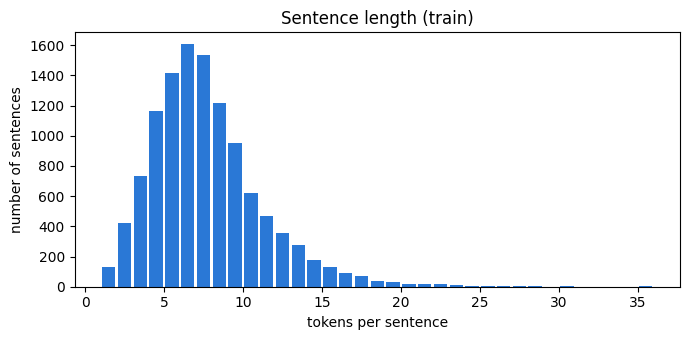

In [6]:
import matplotlib.pyplot as plt

# Refresh train_df so it has the new column
train_df = df[df["partition"] == "train"].copy()

# Histogram of sentence lengths in train
plt.figure(figsize=(7, 3.5))
plt.hist(train_df["n_tokens"], bins=range(1, 37), color="#2a78d6", rwidth=0.85)
plt.title("Sentence length (train)")
plt.xlabel("tokens per sentence")
plt.ylabel("number of sentences")
plt.tight_layout()
plt.show()

In [7]:
# Group lengths into buckets, used later to compare errors by length
df["len_bucket"] = pd.cut(df["n_tokens"], bins=[0, 3, 5, 8, 12, 1000],
                          labels=["1-3", "4-5", "6-8", "9-12", "13+"])

print(pd.crosstab(df["len_bucket"], df["partition"]))

partition   dev  test  train
len_bucket                  
1-3         229   344   1288
4-5         468   708   2580
6-8         778  1110   4356
9-12        414   599   2395
13+         144   213    895


In [8]:
# Look at the longest sentences
df.sort_values("n_tokens", ascending=False)[["partition", "n_tokens", "intent", "utt"]].head(5)

,partition,n_tokens,intent,utt
11242,test,61,recommendation_events,both young drivers and provisional drivers cra...
9871,train,35,cooking_recipe,start the gas stove adjust the flame to cookin...
12215,train,35,transport_taxi,book a taxi to pick up shelley hennessey at ga...
14284,test,33,qa_factoid,what is a neutral density filter and would i w...
6938,train,30,email_sendemail,please send a mail to mr. richard stating that...


**Observations**
- Sentences are short. Median is 7 tokens, and 99% are 18 tokens or less.
- Train, dev and test have almost the same lengths, so length isn't a split issue.
- A few sentences are very long. The longest test sentence (61 tokens) is longer than anything in train
  and reads like an article, not a request. Likely an error case.
- About 11% of train sentences are only 1-3 tokens.
- The tokenizer splits contractions, e.g. "what's" -> "what", "'", "s".

## 03: Examples per intent
Count examples per intent to check for imbalance.

In [9]:
# Count examples per intent in each split
intent_counts = pd.crosstab(df["intent"], df["partition"])[["train", "dev", "test"]]
intent_counts = intent_counts.sort_values("train", ascending=False)

print("Number of intents:", len(intent_counts))
print("\nTraining examples per intent:")
print(intent_counts["train"].describe().round(2))

Number of intents: 60

Training examples per intent:
count     60.00
mean     191.90
std      175.21
min        4.00
25%       77.50
50%      128.50
75%      212.00
max      810.00
Name: train, dtype: float64


In [10]:
# How imbalanced are the intents?
largest = intent_counts["train"].max()
smallest = intent_counts["train"].min()

print("Largest intent:", intent_counts["train"].idxmax(), "-", largest)
print("Smallest intent:", intent_counts["train"].idxmin(), "-", smallest)
print("Imbalance ratio (largest / smallest):", round(largest / smallest, 2))

Largest intent: calendar_set - 810
Smallest intent: cooking_query - 4
Imbalance ratio (largest / smallest): 202.5


In [11]:
# Most and least frequent intents
print("Most frequent intents:")
print(intent_counts.head(10))

print("\nLeast frequent intents:")
print(intent_counts.tail(10))

Most frequent intents:
partition        train  dev  test
intent                           
calendar_set       810  131   209
play_music         639  123   176
weather_query      573  126   156
calendar_query     566  102   126
general_quirky     555  105   169
qa_factoid         544   90   141
news_query         503   82   124
email_query        418   73   119
email_sendemail    354   63   114
datetime_query     350   64    88

Least frequent intents:
partition           train  dev  test
intent                              
iot_wemo_off           52    5    18
datetime_convert       52    9    15
audio_volume_down      52    8    11
music_settings         51    8     6
iot_wemo_on            48    7    10
general_greet          25    2     1
iot_hue_lighton        22    5     3
audio_volume_other     18    0     6
music_dislikeness      14    2     4
cooking_query           4    2     0


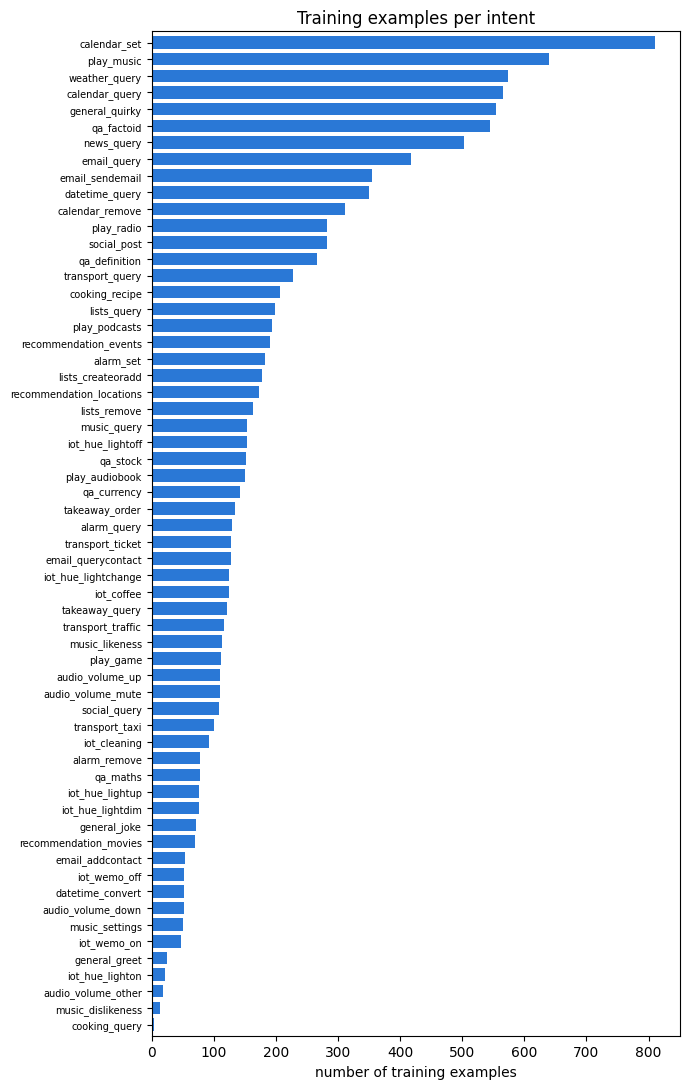

In [12]:
# Bar chart of training examples per intent
plt.figure(figsize=(7, 11))
counts = intent_counts["train"].sort_values()
plt.barh(counts.index, counts.values, color="#2a78d6", height=0.75)
plt.title("Training examples per intent")
plt.xlabel("number of training examples")
plt.yticks(fontsize=7)
plt.margins(y=0.005)
plt.tight_layout()
plt.show()

In [13]:
# How much of the test set do the rare intents make up?
rare = intent_counts[intent_counts["train"] <= 25]
print("Rare intents (25 or fewer training examples):")
print(rare)
print("\nShare of test set:", rare["test"].sum(), "/", intent_counts["test"].sum(),
      f"= {100 * rare['test'].sum() / intent_counts['test'].sum():.2f}%")

Rare intents (25 or fewer training examples):
partition           train  dev  test
intent                              
general_greet          25    2     1
iot_hue_lighton        22    5     3
audio_volume_other     18    0     6
music_dislikeness      14    2     4
cooking_query           4    2     0

Share of test set: 14 / 2974 = 0.47%


**Observations**
- 60 intents, very imbalanced. Largest / smallest = 202.5.
- 5 intents have 25 or fewer training examples. Their dev/test counts are tiny (cooking_query has 0 test,
  audio_volume_other has 0 dev), so their accuracy can't be trusted.
- Rare intents are only 0.47% of test, so they barely affect accuracy. Imbalance isn't the main problem.
- Most rare intents have a common sibling (e.g. iot_hue_lighton vs iot_hue_lightoff). The model will
  probably predict the common one. To check after training.

## 04: Similar intents (scenarios)
Intents in the same scenario use similar words, so they might get mixed up. Check which scenarios have the most intents and how similar they are.

In [14]:
# Number of intents and training examples per scenario
scenario_summary = train_df.groupby("scenario").agg(
    n_intents=("intent", "nunique"),
    n_train=("intent", "size")
).sort_values("n_intents", ascending=False)

print(scenario_summary)

                n_intents  n_train
scenario                          
iot                     9      769
qa                      5     1183
play                    5     1377
music                   4      332
audio                   4      290
transport               4      571
email                   4      953
recommendation          3      433
alarm                   3      390
lists                   3      539
general                 3      652
calendar                3     1688
datetime                2      402
cooking                 2      211
social                  2      391
takeaway                2      257
news                    1      503
weather                 1      573


In [15]:
# List the intents inside each scenario
for scenario, intents in train_df.groupby("scenario")["intent"].unique().items():
    print(f"{scenario}: {sorted(intents)}")

alarm: ['alarm_query', 'alarm_remove', 'alarm_set']
audio: ['audio_volume_down', 'audio_volume_mute', 'audio_volume_other', 'audio_volume_up']
calendar: ['calendar_query', 'calendar_remove', 'calendar_set']
cooking: ['cooking_query', 'cooking_recipe']
datetime: ['datetime_convert', 'datetime_query']
email: ['email_addcontact', 'email_query', 'email_querycontact', 'email_sendemail']
general: ['general_greet', 'general_joke', 'general_quirky']
iot: ['iot_cleaning', 'iot_coffee', 'iot_hue_lightchange', 'iot_hue_lightdim', 'iot_hue_lightoff', 'iot_hue_lighton', 'iot_hue_lightup', 'iot_wemo_off', 'iot_wemo_on']
lists: ['lists_createoradd', 'lists_query', 'lists_remove']
music: ['music_dislikeness', 'music_likeness', 'music_query', 'music_settings']
news: ['news_query']
play: ['play_audiobook', 'play_game', 'play_music', 'play_podcasts', 'play_radio']
qa: ['qa_currency', 'qa_definition', 'qa_factoid', 'qa_maths', 'qa_stock']
recommendation: ['recommendation_events', 'recommendation_locations

In [16]:
# Show a few example sentences for each intent in one scenario
def show_scenario_examples(scenario, n=3):
    subset = train_df[train_df["scenario"] == scenario]
    for intent, group in subset.groupby("intent"):
        print(f"\n{intent}:")
        for utt in group["utt"].sample(n, random_state=42):
            print("   ", utt)

show_scenario_examples("calendar")


calendar_query:
    tell me what my next events are
    do i have a game on april seven
    do i have a meeting tomorrow

calendar_remove:
    erase events
    please cancel all my events for today
    delete the party on june first from my calendar

calendar_set:
    send a notification to friend
    mark thirteen october of this year as my birthday
    create new event on calendar john's birthday


In [17]:
from collections import Counter

# Most common words for each intent in one scenario
def top_words_per_intent(scenario, n=8):
    subset = train_df[train_df["scenario"] == scenario]
    for intent, group in subset.groupby("intent"):
        words = Counter(token for utt in group["utt"] for token in tokenize(utt))
        print(f"{intent:<25} {[word for word, _ in words.most_common(n)]}")

top_words_per_intent("calendar")
print()
top_words_per_intent("iot")

calendar_query            ['what', 'the', 'i', 'is', 'my', 'have', 'do', 'for']
calendar_remove           ['calendar', 'my', 'the', 'delete', 'all', 'remove', 'event', 'events']
calendar_set              ['to', '.', 'me', 'my', 'meeting', 'at', 'a', 'for']

iot_cleaning              ['vacuum', 'the', 'cleaner', 'robot', 'on', 'start', 'turn', 'to']
iot_coffee                ['coffee', 'make', 'a', 'me', 'i', 'olly', 'please', 'of']
iot_hue_lightchange       ['the', 'to', 'lights', 'change', 'light', 'color', 'blue', 'please']
iot_hue_lightdim          ['the', 'lights', 'dim', 'in', 'down', 'please', 'lower', 'turn']
iot_hue_lightoff          ['off', 'the', 'turn', 'lights', 'light', 'in', 'room', 'please']
iot_hue_lighton           ['on', 'lights', 'the', 'turn', "'", 'it', 'dark', 'please']
iot_hue_lightup           ['the', 'lights', 'light', 'up', 'turn', 'please', 'brighten', 'increase']
iot_wemo_off              ['off', 'socket', 'turn', 'the', 'plug', 'wemo', 'smart', 'please']
io

In [18]:
# How often do small "filler" words appear in sibling intents?
key_words = ["on", "off", "up", "down"]
iot_subset = train_df[train_df["intent"].isin(
    ["iot_hue_lighton", "iot_hue_lightoff", "iot_hue_lightup", "iot_hue_lightdim"])]

for word in key_words:
    has_word = iot_subset["utt"].map(lambda utt: word in tokenize(utt))
    print(f"'{word}':")
    print((100 * has_word.groupby(iot_subset["intent"]).mean()).round(2).to_string(), "\n")

'on':
intent
iot_hue_lightdim     1.32
iot_hue_lightoff     1.31
iot_hue_lighton     68.18
iot_hue_lightup      1.32 

'off':
intent
iot_hue_lightdim     0.00
iot_hue_lightoff    88.89
iot_hue_lighton      0.00
iot_hue_lightup      0.00 

'up':
intent
iot_hue_lightdim     1.32
iot_hue_lightoff     0.00
iot_hue_lighton      0.00
iot_hue_lightup     26.32 

'down':
intent
iot_hue_lightdim    22.37
iot_hue_lightoff     0.00
iot_hue_lighton      0.00
iot_hue_lightup      1.32 



In [19]:
# Also look at the qa scenario
show_scenario_examples("qa")


qa_currency:
    please let me know the exchange rate between indian rupees and us
    what is the exchange rate for u. s. d. to nzd
    what is the dollar against the pound

qa_definition:
    can you tell me what a grommet is
    please define the word hypocrisy
    what is the definition of mutual

qa_factoid:
    what is the distance to the moon
    tell me about donald trump
    what color is a basketball

qa_maths:
    what is two plus four
    ten percentages of hundred
    i've got dollars for the month how much can i spend every day this month

qa_stock:
    is chase doing good
    compare the stock prices for nintendo and sony and tell me which ones are better
    tell me summary forecast microsoft stock forecast to thirty days ahead


**Observations**
- iot has 9 intents, qa and play have 5. These are the most likely to get mixed up.
- Sibling intents share most of their words. Often one small word decides the intent:
  on/off (lighton vs lightoff), up/down (lightup vs lightdim), what/delete/create (calendar).
- "off" is in 88.89% of lightoff sentences and 0% of its siblings, so these words matter a lot.
- These words are in standard stopword lists, so removing stopwords would break these intents.
- About a third of lighton sentences don't have "on" (e.g. "it's dark in here"). Those are harder.
- up/down only show up in about a quarter of lightup/lightdim sentences. Wording is more varied.
- In qa, most sentences start with "what is" / "tell me", so only the topic word decides the intent.
  Cues can overlap (e.g. "dollars" in a qa_maths sentence).
- qa_factoid is a catch-all and might get mixed up with general_quirky (different scenario).
- Some labels look off (e.g. "send a notification to friend" -> calendar_set). See Step 7.
- Hypothesis: most intent errors will be between siblings. To check after training.

## 05: Slot types
Check how many slots each sentence has, how common each slot type is and how long the spans are.

In [20]:
# Same slot pattern as main.ipynb: [type : words]
slot_pattern = re.compile(r'\[\s*([^:\[\]]+?)\s*:\s*([^\[\]]*?)\]')

def extract_slots(annot_utt):
    return [(slot_type.strip(), slot_text) for slot_type, slot_text in slot_pattern.findall(annot_utt)]

# Example
print(extract_slots("wake me up at [time : five am] [date : this week]"))

# Slots for every sentence
df["slots"] = df["annot_utt"].map(extract_slots)
df["n_slots"] = df["slots"].map(len)

# Refresh splits so they have the new columns
train_df = df[df["partition"] == "train"].copy()
dev_df = df[df["partition"] == "dev"].copy()
test_df = df[df["partition"] == "test"].copy()

[('time', 'five am'), ('date', 'this week')]


In [21]:
# Slots per sentence
print("Slots per sentence:")
print(df.groupby("partition")["n_slots"].describe().round(2))

# Share of sentences with no slots
no_slots = df.groupby("partition")["n_slots"].apply(lambda n: 100 * (n == 0).mean())
print("\n% of sentences with no slots:")
print(no_slots.round(2))

Slots per sentence:
             count  mean   std  min  25%  50%  75%  max
partition                                              
dev         2033.0  0.99  0.89  0.0  0.0  1.0  1.0  5.0
test        2974.0  0.95  0.88  0.0  0.0  1.0  1.0  5.0
train      11514.0  0.99  0.91  0.0  0.0  1.0  1.0  7.0

% of sentences with no slots:
partition
dev      31.78
test     33.42
train    32.61
Name: n_slots, dtype: float64


In [22]:
# Count each slot type in each split
def count_slot_types(split_df):
    return Counter(slot_type for slots in split_df["slots"] for slot_type, _ in slots)

slot_counts = pd.DataFrame({
    "train": count_slot_types(train_df),
    "dev": count_slot_types(dev_df),
    "test": count_slot_types(test_df)
}).fillna(0).astype(int).sort_values("train", ascending=False)

print("Number of slot types:", len(slot_counts))
print("\nMost frequent slot types:")
print(slot_counts.head(10))
print("\nLeast frequent slot types:")
print(slot_counts.tail(10))

Number of slot types: 55

Most frequent slot types:
                    train  dev  test
date                 1816  339   416
place_name           1086  209   281
event_name            998  160   260
person                864  132   219
time                  797  137   193
media_type            477   98   128
business_name         383   58    92
weather_descriptor    320   59    82
transport_type        318   54    65
food_type             295   51    72

Least frequent slot types:
                      train  dev  test
movie_name               16    2     2
movie_type               10    1     3
transport_name            9    2     4
drink_type                9    3     1
alarm_type                9    2     3
transport_descriptor      8    0     2
audiobook_author          6    1     5
sport_type                5    1     0
music_album               1    0     1
game_type                 1    1     0


In [23]:
# How much of the test set do the top 10 slot types make up?
top10 = slot_counts.head(10)
print("Top 10 slot types share of test slots:",
      top10["test"].sum(), "/", slot_counts["test"].sum(),
      f"= {100 * top10['test'].sum() / slot_counts['test'].sum():.2f}%")

Top 10 slot types share of test slots: 1808 / 2815 = 64.23%


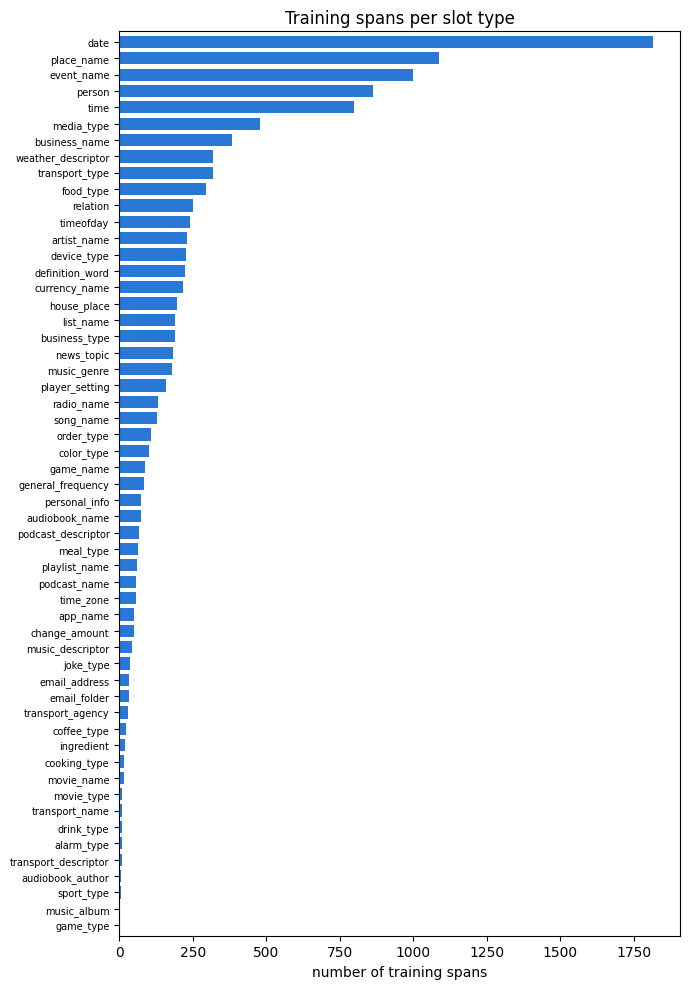

In [24]:
# Bar chart of training spans per slot type
plt.figure(figsize=(7, 10))
counts = slot_counts["train"].sort_values()
plt.barh(counts.index, counts.values, color="#2a78d6", height=0.75)
plt.title("Training spans per slot type")
plt.xlabel("number of training spans")
plt.yticks(fontsize=7)
plt.margins(y=0.005)
plt.tight_layout()
plt.show()

In [25]:
# How many tokens does a slot span have?
span_lengths = pd.Series([len(tokenize(text)) for slots in train_df["slots"] for _, text in slots])
print("Slot span length in tokens (train):")
print(span_lengths.describe().round(2))
print("\nSpans by length:")
print(span_lengths.value_counts().sort_index().head(8))

Slot span length in tokens (train):
count    11344.00
mean         1.76
std          1.29
min          1.00
25%          1.00
50%          1.00
75%          2.00
max         12.00
dtype: float64

Spans by length:
1    6764
2    2754
3     857
4     274
5     394
6     199
7      45
8      30
Name: count, dtype: int64


In [26]:
# Average span length per slot type (types with at least 50 training spans)
span_df = pd.DataFrame(
    [(slot_type, len(tokenize(text))) for slots in train_df["slots"] for slot_type, text in slots],
    columns=["slot_type", "span_length"]
)
span_by_type = span_df.groupby("slot_type")["span_length"].agg(["count", "mean"]).round(2)
span_by_type = span_by_type[span_by_type["count"] >= 50].sort_values("mean", ascending=False)

print("Longest spans on average:")
print(span_by_type.head(8))
print("\nShortest spans on average:")
print(span_by_type.tail(5))

Longest spans on average:
                    count  mean
slot_type                      
radio_name            131  4.12
time                  797  3.22
audiobook_name         73  2.75
song_name             128  2.48
podcast_name           56  2.27
playlist_name          62  2.21
podcast_descriptor     68  2.19
currency_name         217  2.16

Shortest spans on average:
                count  mean
slot_type                  
app_name           51  1.20
timeofday         239  1.11
color_type        100  1.08
meal_type          63  1.05
transport_type    318  1.00


**Observations**
- Most sentences have 1 slot, and about a third have none. Any slot predicted there counts as wrong.
- 55 slot types. The top 10 make up 64.23% of test slots, so they basically decide slot F1.
- Some types are super rare (music_album and game_type have 1 training example each), but the bottom 10
  are under 1% of test slots, so they barely matter.
- About 60% of slot spans are 1 token. Longer spans are harder since every word must match.
- time is common and long (3.22 tokens on average, e.g. "two hours from now"). Likely a big source of
  slot errors. Name slots (radio_name, song_name, audiobook_name) are long too.

## 06: Unseen words (OOV)
Our vocab is built from train only, so new words in dev/test become `<UNK>`. Check how often this happens and where.

In [27]:
# Vocabulary built from training sentences only (same as main.ipynb)
train_vocab = Counter(token for utt in train_df["utt"] for token in tokenize(utt))

print("Training vocabulary size:", len(train_vocab))
seen_once = sum(1 for count in train_vocab.values() if count == 1)
print(f"Words seen only once: {seen_once} ({100 * seen_once / len(train_vocab):.2f}%)")

# Embedding parameters = vocab size x embedding dimension
for dim in [100, 300]:
    n_params = len(train_vocab) * dim
    print(f"Embedding parameters at dim {dim}: {n_params:,} ({100 * n_params / 20_000_000:.2f}% of 20M)")

Training vocabulary size: 5144
Words seen only once: 2420 (47.05%)
Embedding parameters at dim 100: 514,400 (2.57% of 20M)
Embedding parameters at dim 300: 1,543,200 (7.72% of 20M)


In [28]:
# Split each sentence into slot tokens and non-slot tokens
def slot_and_other_tokens(annot_utt):
    slot_tokens = [token for _, text in extract_slots(annot_utt) for token in tokenize(text)]
    other_tokens = tokenize(slot_pattern.sub(" ", annot_utt))
    return slot_tokens, other_tokens

print(slot_and_other_tokens("wake me up at [time : five am] [date : this week]"))

(['five', 'am', 'this', 'week'], ['wake', 'me', 'up', 'at'])


In [29]:
# OOV rate inside slots vs outside slots
def oov_rate(tokens):
    return 100 * sum(token not in train_vocab for token in tokens) / len(tokens)

for name, split_df in [("dev", dev_df), ("test", test_df)]:
    slot_tokens, other_tokens = [], []
    for annot in split_df["annot_utt"]:
        s, o = slot_and_other_tokens(annot)
        slot_tokens += s
        other_tokens += o

    has_oov = split_df["utt"].map(lambda utt: any(t not in train_vocab for t in tokenize(utt)))

    print(f"{name}:")
    print(f"   OOV % (slot tokens):  {oov_rate(slot_tokens):.2f}")
    print(f"   OOV % (other tokens): {oov_rate(other_tokens):.2f}")
    print(f"   % sentences with at least 1 OOV word: {100 * has_oov.mean():.2f}")

dev:
   OOV % (slot tokens):  6.91
   OOV % (other tokens): 1.88
   % sentences with at least 1 OOV word: 17.27
test:
   OOV % (slot tokens):  7.60
   OOV % (other tokens): 1.89
   % sentences with at least 1 OOV word: 18.19


In [30]:
# Which slot types have the most OOV words? (test set)
rows = []
for slots in test_df["slots"]:
    for slot_type, text in slots:
        tokens = tokenize(text)
        rows.append((slot_type, any(t not in train_vocab for t in tokens)))

oov_by_type = pd.DataFrame(rows, columns=["slot_type", "has_oov"])
oov_by_type = oov_by_type.groupby("slot_type")["has_oov"].agg(["count", "mean"])
oov_by_type["mean"] = (100 * oov_by_type["mean"]).round(2)
oov_by_type = oov_by_type.rename(columns={"mean": "% spans with OOV"})

print(oov_by_type[oov_by_type["count"] >= 20].sort_values("% spans with OOV", ascending=False).head(10))

                 count  % spans with OOV
slot_type                               
game_name           26             50.00
definition_word     51             35.29
audiobook_name      23             34.78
artist_name         61             31.15
business_name       92             29.35
person             219             28.77
news_topic          49             22.45
food_type           72             19.44
song_name           39             17.95
radio_name          33             15.15


In [31]:
# Most common OOV words in test
test_oov = Counter(t for utt in test_df["utt"] for t in tokenize(utt) if t not in train_vocab)
print(test_oov.most_common(25))

[('drivers', 4), ('suck', 3), ('saga', 3), ('vergara', 3), ('mexico', 3), ('summarize', 2), ('academy', 2), ('mostly', 2), ('angels', 2), ('terrorism', 2), ('reggae', 2), ('knock', 2), ('socks', 2), ('suggestion', 2), ('expected', 2), ('default', 2), ('glass', 2), ('cover', 2), ('tires', 2), ('musics', 2), ('tips', 2), ('searches', 2), ('plants', 2), ('parents', 2), ('feb', 2)]


In [32]:
# Are some OOV words just variants of words already in the training vocabulary?
variants = {"musics": "music", "searches": "search", "parents": "parent", "drivers": "driver",
            "socks": "sock", "tires": "tire", "expected": "expect", "feb": "february"}

for oov_word, base_word in variants.items():
    print(f"{oov_word:<10} -> {base_word:<10} base form in train vocab: {base_word in train_vocab}")

musics     -> music      base form in train vocab: True
searches   -> search     base form in train vocab: True
parents    -> parent     base form in train vocab: True
drivers    -> driver     base form in train vocab: True
socks      -> sock       base form in train vocab: True
tires      -> tire       base form in train vocab: True
expected   -> expect     base form in train vocab: True
feb        -> february   base form in train vocab: True


In [33]:
import gensim.downloader as api

# Same GloVe model as main.ipynb
glove = api.load("glove-wiki-gigaword-100")

# How many unseen test words does GloVe actually have a vector for?
unique_oov = set(test_oov)
in_glove = [word for word in unique_oov if word in glove]
print(f"Unique unseen test words: {len(unique_oov)}")
print(f"Of which GloVe has a vector for: {len(in_glove)} ({100 * len(in_glove) / len(unique_oov):.2f}%)")
print("Not in GloVe:", sorted(unique_oov - set(in_glove))[:20])

[==================================================] 100.0% 128.1/128.1MB downloaded
Unique unseen test words: 623
Of which GloVe has a vector for: 571 (91.65%)
Not in GloVe: ['allearsnet', 'altnon', 'bhuli', 'bilando', 'cookingforu', 'crytals', 'cstm', 'dogwalking', 'emailstudy', 'fitzgerals', 'fransico', 'gagas', 'googs', 'gretszky', 'grigorean', 'hardword', 'harrypotter', 'hayathis', 'hipsterhood', 'juanpedro']


**Observations**
- Train vocab is 5,144 words, and 47% appear only once. At dim 100, embeddings use only 2.57% of the
  20M limit, so there's a lot of room left.
- Unseen words are about 4x more common inside slots (7.60% vs 1.89% on test). About 18% of test
  sentences have at least one. This mostly hurts slot F1.
- Name slots have the most unseen words (game_name, artist_name, audiobook_name). person matters most:
  it's a top-5 type and about 29% of its test spans have an unseen word.
- Many unseen words are just variants of known words (searches -> search, parents -> parent).
- GloVe has vectors for 91.65% of unseen test words. They only become `<UNK>` because our vocab is
  built from train only.
- The rest are typos (fransico), joined words (harrypotter) or rare names. Only char-level features
  would help with those.
- Possible Stage 2 ideas: lemmatization, char-level features, or a bigger GloVe vocab (check with prof).

## 07: Weird labels
Check if any labels are inconsistent or wrong.

In [34]:
# 1. Same sentence, different intent (training set)
intents_per_utt = train_df.groupby("utt")["intent"].nunique()
conflicting = intents_per_utt[intents_per_utt > 1].index

print("Training sentences with more than one intent label:", len(conflicting))
print(train_df[train_df["utt"].isin(conflicting)].sort_values("utt")[["utt", "intent"]])

Training sentences with more than one intent label: 4
                                                   utt                 intent
1932                                        good night      audio_volume_mute
3473                                        good night       iot_hue_lightoff
6504      olly book me a taxi to leith in half an hour        calendar_remove
11692     olly book me a taxi to leith in half an hour         transport_taxi
3513                  olly play be warned by tech nine             play_music
6932                  olly play be warned by tech nine           calendar_set
2946   olly what movies are playing at carmike cinemas         takeaway_order
11646  olly what movies are playing at carmike cinemas  recommendation_movies


In [35]:
# 2. Same words, different slot type (training set)
from collections import defaultdict

types_per_text = defaultdict(Counter)
for slots in train_df["slots"]:
    for slot_type, text in slots:
        types_per_text[text][slot_type] += 1

conflicting_spans = [(text, dict(types)) for text, types in types_per_text.items() if len(types) > 1]
conflicting_spans = sorted(conflicting_spans, key=lambda x: -sum(x[1].values()))

print("Span texts labelled with more than one slot type:", len(conflicting_spans))
for text, types in conflicting_spans[:15]:
    print(f"   {text:<20} {types}")

Span texts labelled with more than one slot type: 182
   train                {'news_topic': 1, 'event_name': 1, 'transport_type': 240}
   birthday             {'event_name': 73, 'date': 1}
   facebook             {'media_type': 66, 'business_name': 4}
   tonight              {'timeofday': 61, 'date': 1}
   tuesday              {'date': 57, 'event_name': 1}
   this weekend         {'date': 47, 'time': 1}
   shopping             {'event_name': 1, 'list_name': 40, 'business_type': 3}
   world                {'place_name': 40, 'news_topic': 1}
   wednesday            {'date': 34, 'list_name': 1}
   grocery              {'list_name': 31, 'business_type': 1}
   yesterday            {'song_name': 1, 'date': 29}
   uber                 {'transport_agency': 28, 'definition_word': 1, 'business_name': 1}
   c. n. n.             {'media_type': 28, 'radio_name': 1}
   blue                 {'color_type': 28, 'music_genre': 1}
   appointments         {'event_name': 25, 'list_name': 2}


In [36]:
# 3. Words that are only sometimes inside a slot
inside, total = Counter(), Counter()
for annot in train_df["annot_utt"]:
    slot_tokens, other_tokens = slot_and_other_tokens(annot)
    for token in slot_tokens:
        inside[token] += 1
        total[token] += 1
    for token in other_tokens:
        total[token] += 1

boundary = pd.DataFrame(
    [(word, total[word], inside[word]) for word in total if total[word] >= 50],
    columns=["word", "count", "inside_slot"]
)
boundary["% inside slot"] = (100 * boundary["inside_slot"] / boundary["count"]).round(2)

print("Common words inside a slot 25-75% of the time:")
print(boundary[boundary["% inside slot"].between(25, 75)].sort_values("count", ascending=False).head(15))

Common words inside a slot 25-75% of the time:
         word  count  inside_slot  % inside slot
51          '    952          354          37.18
52          s    861          409          47.50
77       this    743          251          33.78
155       new    478          120          25.10
134      next    381          156          40.94
1          am    307          221          71.99
41        one    198          107          54.04
118       day    194           51          26.29
7         two    191          129          67.54
110      last    147           56          38.10
95   playlist    132           34          25.76
123     three    123           89          72.36
143       out    113           31          27.43
145      take    105           27          25.71
56          t    100           27          27.00


In [37]:
# Look at examples of one ambiguous word, in and out of a slot
def show_word_examples(word, n=4):
    has_word = train_df[train_df["utt"].map(lambda utt: word in tokenize(utt))]
    in_slot = has_word[has_word["slots"].map(lambda slots: any(word in tokenize(t) for _, t in slots))]
    not_in_slot = has_word.drop(in_slot.index)
    print(f"'{word}' inside a slot:")
    for a in in_slot["annot_utt"].sample(n, random_state=42):
        print("   ", a)
    print(f"'{word}' outside a slot:")
    for a in not_in_slot["annot_utt"].sample(n, random_state=42):
        print("   ", a)

show_word_examples("next")

'next' inside a slot:
    play the [podcast_descriptor : next episode]
    will you remind me of my [event_name : next dentist appointment] [date : one day before]
    add to calendar an [event_name : medical appointment] for the [time : first day of the next five months]
    delete everything on my calendar for [time : the next two weeks]
'next' outside a slot:
    what's next in my calendar
    when is the next lakers game
    set an [time : eight hundred am] alarm for next [date : tuesday]
    play next [podcast_name : nutritional facts]


**Observations**
- Only 4 train sentences have conflicting intents. "good night" is genuinely ambiguous, the rest are
  just wrong labels (e.g. "book me a taxi..." -> calendar_remove).
- 182 span texts have more than one slot type. Some depend on context ("facebook" as media_type vs
  business_name), some are one-off mistakes ("train" as news_topic once vs transport_type 240 times).
- Some words are only sometimes inside a slot: "'s", this/next/last, and number/time words (one, two, am).
- Slot boundaries aren't consistent. "next" is left out in "alarm for next [date : tuesday]" but
  included in "[time : the next two weeks]". "when is the next lakers game" has no slot at all.
- So some errors (especially date/time) aren't the model's fault. No model can match inconsistent labels.

## 08: How much do slots depend on the intent?
The cascade passes intent info to the slot part. Check if slot types actually depend on the intent.

In [38]:
# For each slot type: how many intents/scenarios it appears in, and the share in its most common scenario
rows = [(slot_type, intent, scenario)
        for slots, intent, scenario in zip(train_df["slots"], train_df["intent"], train_df["scenario"])
        for slot_type, _ in slots]
slot_ctx = pd.DataFrame(rows, columns=["slot_type", "intent", "scenario"])

dependence = slot_ctx.groupby("slot_type").agg(
    count=("intent", "size"),
    n_intents=("intent", "nunique"),
    n_scenarios=("scenario", "nunique"),
    top_scenario_share=("scenario", lambda s: round(100 * s.value_counts(normalize=True).iloc[0], 2))
).sort_values("count", ascending=False)

concentrated = (dependence["top_scenario_share"] >= 90).sum()
print(f"Slot types with 90%+ of spans in one scenario: {concentrated} / {len(dependence)}")
print(dependence.head(12))

# How many different slot types does each intent use?
types_per_intent = slot_ctx.groupby("intent")["slot_type"].nunique()
print("\nSlot types used per intent: median", types_per_intent.median(), "| max", types_per_intent.max())

Slot types with 90%+ of spans in one scenario: 33 / 55
                    count  n_intents  n_scenarios  top_scenario_share
slot_type                                                            
date                 1816         40           17               45.48
place_name           1086         25           14               32.60
event_name            998         25           14               85.37
person                864         24           12               45.37
time                  797         35           16               46.30
media_type            477         13            9               56.60
business_name         383         16           10               36.29
weather_descriptor    320          1            1              100.00
transport_type        318          6            4               98.43
food_type             295          9            6               50.85
relation              251         18            8               54.58
timeofday             239         2

**Observations**
- 33 of 55 slot types are 90%+ in one scenario, and each intent uses only about 8 slot types.
  So knowing the intent narrows down the slots, which supports the cascade design.
- But date, time, place_name and person show up in 12-17 scenarios, so intent helps them less.
  These types decide most of slot F1, so the cascade gain might be smaller than expected.

## Summary

### Key findings

| # | Finding | Evidence | Why it matters |
|---|---|---|---|
| 1 | Sentences are short | Median 7 tokens, 99% have 18 or fewer | Little context per sentence; very short ones (11% have 1-3 tokens) are hard |
| 2 | Intents are very imbalanced | Largest / smallest = 202.5; 5 intents have 25 or fewer examples | Rare intents will be poorly learned, but they are only 0.47% of test, so they barely affect accuracy |
| 3 | Sibling intents are easily confused | One small word often decides the intent ("off" in 88.89% of lightoff, 0% of siblings) | Likely the main source of intent errors |
| 4 | Slot F1 is decided by a few types | Top 10 slot types = 64.23% of test slots | Improving date, place_name, person and time matters most |
| 5 | time slots are frequent and long | Average span 3.22 tokens | Every word must match, so time is likely a major source of slot errors |
| 6 | Unseen words are concentrated in slots | 7.60% of slot tokens vs 1.89% of other tokens (test); 18% of test sentences have one | Mainly hurts slot F1, especially person (29% of spans contain an unseen word) |
| 7 | Most unseen words are known to GloVe | GloVe covers 91.65% of unique unseen test words | They become `<UNK>` only because the vocabulary is built from training sentences |
| 8 | Labels are sometimes inconsistent | 4 conflicting intent duplicates, 182 span texts with multiple slot types, inconsistent date/time boundaries ("next") | Sets a ceiling on performance; some errors are not the model's fault |
| 9 | Slot types depend on the intent | 33 of 55 slot types are 90%+ in one scenario; each intent uses ~8 slot types | Supports passing intent info to slot filling (cascade), but common types (date, time, place, person) benefit less |

### Hypotheses to verify
1. Most intent errors are between sibling intents in the same scenario.
2. Rare intents are predicted as their common sibling (e.g. iot_hue_lighton -> iot_hue_lightoff).
3. Slot F1 is lower for sentences with unseen words.
4. time and person are the slot types with the most errors.
5. Many date/time errors are boundary errors (e.g. "next tuesday" vs "tuesday").
6. The 61-token test sentence and other long outliers are predicted wrongly.
7. The cascade improves slot F1 more for scenario-specific slot types (e.g. weather_descriptor) than for date, time, place_name and person.